In [2]:
import cv2 
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
import tensorflow as tensorflow
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import random
import sys

In [4]:
DATASET_ROOT = 'Dataset'
OUTPUT_FILE = 'dataset_kilter.csv'

OFFSET_X = 12.0
SCALE_X = 14.45
OFFSET_Y = 271.0   # cv2 a l'origine a l'axe Y inversé, donc on prend le bas de l'image comme origine
SCALE_Y = 14.3        # Zoom
CORRECTION_Y = -1.5 #Correction arbitraire  

# Bornes HSV pour chaque couleur de prise
COLORS = {
    'start':  {'lower': np.array([30, 50, 0]), 'upper': np.array([86, 255, 255])}, #vert
    'middle': {'lower': np.array([80, 50, 0]), 'upper': np.array([110, 255, 255])}, #bleu
    'foot':   {'lower': np.array([12, 50, 0]), 'upper': np.array([51, 255, 255])}, #orange
    'top':    {'lower': np.array([95, 50, 0]), 'upper': np.array([179, 255, 255])} #violet
}

# Génération du modèle de la grille Kilterboard avec les coordonnées des prises
def generate_kilter_layout():
    layout = []

    # A. Kickboard
    for row in range(2):
        y = -2 + row
        shift = -0.5 if row == 0 else 0  # Décalage pour la ligne tout en bas
        for col in range(18 - row):
            layout.append({"type": "kickboard", "x": col + shift, "y": y, "label": "K"})

    # B. Prises principales (bolts)
    rows_main_height = 18
    cols_main_width = 17
    for row in range(rows_main_height):
        for col in range(cols_main_width):
            layout.append({"type": "hand_bolt", "x": float(col), "y": float(row), "label": "."})

    # C. Prises de pieds
    for row in range(rows_main_height - 3):
        for col in range(-1, cols_main_width):
            if row % 2 != col % 2:
                layout.append({"type": "foot_screw", "x": col + 0.5, "y": row + 0.5, "label": "x"})

    return layout

LAYOUT = pd.DataFrame(generate_kilter_layout())

def build_candidates(types):
    sub = LAYOUT[LAYOUT['type'].isin(types)].reset_index(drop=True) # Compare la colonne 'type' avec la liste des types fournie et garde uniquement les lignes correspondantes
    return sub['x'].values, sub['y'].values, sub['type'].values

# Mains : bolts uniquement / Pieds : bolts + vis + kickboard
CANDIDATES = {
    'hand': build_candidates(['hand_bolt']),
    'foot': build_candidates(['hand_bolt', 'foot_screw', 'kickboard']),
}

def map_pixel_to_grid(px_x, px_y, role):
    raw_x = (px_x - OFFSET_X) / SCALE_X  # Applications des offsets car l'origine est en haut à gauche de l'image
    raw_y = ((OFFSET_Y - px_y) / SCALE_Y) + CORRECTION_Y

    xs, ys, types = CANDIDATES['foot' if role == 'foot' else 'hand'] # On récupère toutes les prises possibles pour le rôle
    d = np.hypot(xs - raw_x, ys - raw_y) # On calcule la distance entre le point cv2 et toutes les prises de CANDIDATES
    i = int(np.argmin(d)) # On récupère l'index de la prise la plus proche
    return float(xs[i]), float(ys[i]), str(types[i]), float(d[i])

def extract_holds(img_path):
    img = cv2.imread(img_path) # Charge l'image depuis le chemin  
    if img is None:
        return []

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) # Convertit l'image de BGR à HSV (teinte, saturation, valeur) pour faciliter la détection des couleurs
    found = {}

    for role, params in COLORS.items():
        mask = cv2.inRange(hsv, params['lower'], params['upper']) # Créer un masque binaire où les pixels correspondant à la couleur sont blancs (255) et les autres sont noirs (0)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) # Détecte les contours blancs sur le fond noir du masque

        for cnt in contours:
            M = cv2.moments(cnt) # Calcule les moments du contour pour obtenir des informations géométriques, comme le centre
            if M["m00"] == 0:
                continue

            cx = M["m10"] / M["m00"]  # Somme des X dans le contour divisé par l'aire du contour
            cy = M["m01"] / M["m00"]  # Somme des Y dans le contour divisé par l'aire du contour
            x, y, htype, dist = map_pixel_to_grid(cx, cy, role)

            # Dédoublonnage sur le TROU de la grille (plus sur les pixels)
            key = (x, y, role)
            if key not in found or dist < found[key]['snap_dist']:
                found[key] = {'col': x, 'row': y, 'role': role,
                              'hold_type': htype, 'snap_dist': dist}

    return list(found.values())

# Main
all_rows = []

for root, dirs, files in os.walk(DATASET_ROOT):
    folder_name = os.path.basename(root)
    if folder_name.upper().startswith('V'):
        current_grade = folder_name.upper().replace(" ", "")
        image_files = [f for f in files if f.lower().endswith(('.png'))] #Récupère les fichiers d'images

        for f in image_files:
            holds = extract_holds(os.path.join(root, f))
            for h in holds:
                all_rows.append({
                    'image_id': f,
                    'grade': current_grade,
                    'col': h['col'],
                    'row': h['row'],
                    'role': h['role'],
                    'hold_type': h['hold_type'],
                    'snap_dist': h['snap_dist'],
                })

df = pd.DataFrame(all_rows)
df.to_csv(OUTPUT_FILE, index=False)

print(f"Dataset : {OUTPUT_FILE} ({len(df)} lignes, {df['image_id'].nunique()} images)")

print("\nDistance d'erreurs par rôle :")
print(df.groupby('role')['snap_dist'].describe()[['mean', '50%', 'max']])

print("\nNombre de prises par image et par rôle :")
print(df.groupby(['image_id', 'role']).size().unstack(fill_value=0).describe().loc[['min', 'mean', 'max']])

Dataset : dataset_kilter.csv (159091 lignes, 13431 images)

Distance d'erreurs par rôle :
            mean       50%       max
role                                
foot    0.286838  0.292695  0.620417
middle  0.289462  0.280933  1.862211
start   0.311113  0.298211  1.859796
top     0.275704  0.267931  1.309841

Nombre de prises par image et par rôle :
role       foot     middle     start       top
min    0.000000   0.000000  0.000000  0.000000
mean   4.343087   4.788698  1.643437  1.069838
max   31.000000  27.000000  4.000000  5.000000


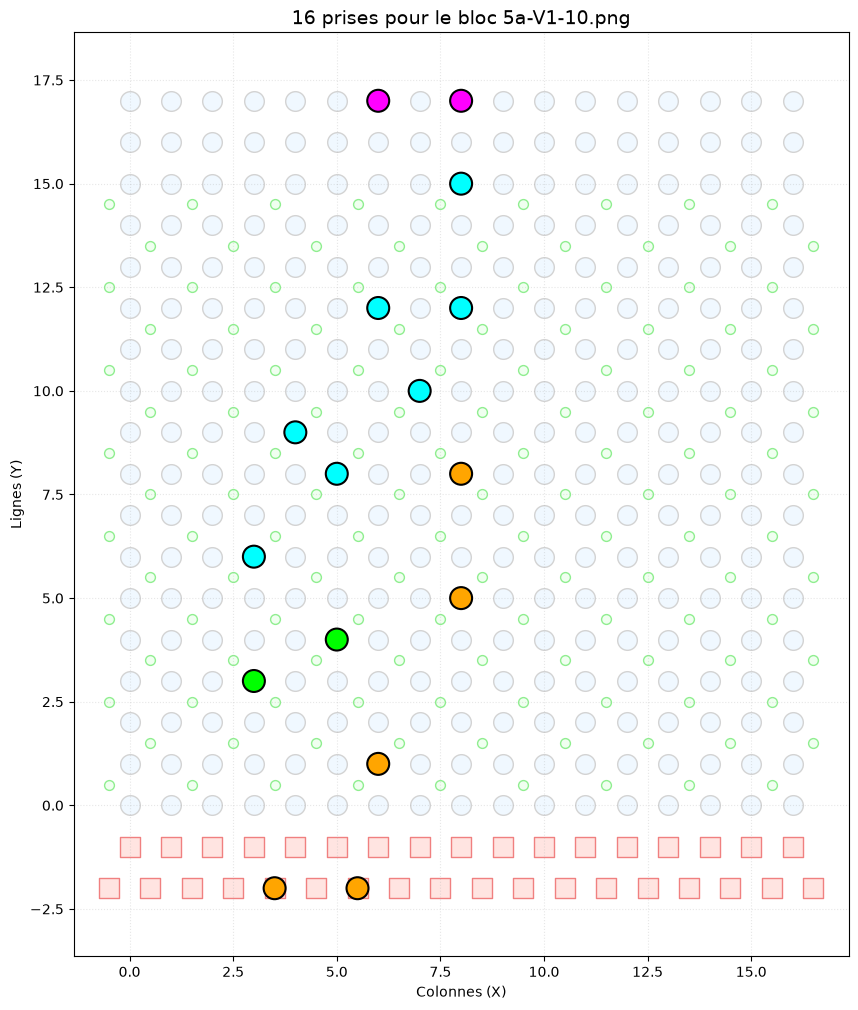

In [27]:
INPUT_FILE = 'dataset_kilter.csv'
TARGET_IMAGE_ID = '5a-V1-10.png'

def visualize_route_on_custom_grid(csv_path, image_id):
    grid = LAYOUT  # défini dans la cellule 1

    bolts = grid[grid['type'] == 'hand_bolt']
    screws = grid[grid['type'] == 'foot_screw']
    kick = grid[grid['type'] == 'kickboard']

    route = pd.DataFrame()
    try:
        data = pd.read_csv(csv_path)
        route = data[data['image_id'] == image_id]
        if route.empty:
            print(f"Aucune donnée trouvée pour {image_id}")
    except FileNotFoundError:
        print("Fichier CSV introuvable")

    plt.figure(figsize=(10, 12))
    plt.gca().set_facecolor('white')

    # Crée la grille de fond avec les prises transparentes
    plt.scatter(bolts['x'], bolts['y'], s=200, c='aliceblue', edgecolors='lightgray', zorder=1)
    plt.scatter(screws['x'], screws['y'], s=50, c='honeydew', edgecolors='lightgreen', zorder=1)
    plt.scatter(kick['x'], kick['y'], s=200, c='mistyrose', edgecolors='lightcoral', marker='s', zorder=1)

    if not route.empty:
        # On defini des couleurs pour chaque rôle de prise
        role_colors = {'start': '#00FF00', 'middle': '#00FFFF', 'foot': '#FFA500', 'top': '#FF00FF'} #On defini des couleurs pour chaque rôle de prise
        
        # n_feet = (route['role'] == 'foot').sum()
        # n_top = (route['role'] == 'top').sum()
        # n_start = (route['role'] == 'start').sum()

        couleurs_prises = route['role'].map(role_colors)


        plt.scatter(route['col'], route['row'], s=250, c=couleurs_prises, edgecolors='black', linewidth=1.5, zorder=10)

    plt.title(f"{len(route)} prises pour le bloc {image_id}", fontsize=14)
    plt.xlabel("Colonnes (X)")
    plt.ylabel("Lignes (Y)")
    plt.ylim(-3, 18)
    plt.xlim(-2, 18)
    plt.grid(True, linestyle=':', alpha=0.3)
    plt.axis('equal')
    plt.show()

visualize_route_on_custom_grid(INPUT_FILE, TARGET_IMAGE_ID)


In [36]:
from scipy.spatial.distance import pdist, squareform

#1. On récupère tes données (ta fonction précédente)
data = generate_kilter_layout()

# 2. On transforme en DataFrame (Tableau Excel intelligent)
df = pd.DataFrame(data)

# 3. Création de l'ID "propre" (sans point, tout x10)
# Ex: Main en x=5.0, y=10.0 devient id="h_50_100"
# Ex: Pied en x=5.5, y=10.5 devient id="f_55_105"
def create_clean_id(row):
    prefix = row['type'][0] # 'h' pour hand, 'f' pour foot, 'k' pour kickboard
    x_clean = int(row['x'] * 10)
    y_clean = int(row['y'] * 10)
    return f"{prefix}_{x_clean}_{y_clean}"

df['id'] = df.apply(create_clean_id, axis=1)

# On définit l'ID comme l'index du tableau pour retrouver les prises facilement
df.set_index('id', inplace=True)

print(f"DataFrame créé avec {len(df)} prises.")
print("Exemple d'IDs générés :", df.index[:5].tolist())

# --- 4. LE COEUR DU RÉACTEUR : La Matrice de Distance ---

# On extrait juste les colonnes X et Y pour le calcul
coords = df[['x', 'y']].values

# pdist calcule toutes les distances Euclidiennes (théorème de Pythagore géant)
distances_array = pdist(coords, metric='euclidean')

# On remet ça sous forme carrée (Tableau Prise x Prise)
dist_matrix = pd.DataFrame(
    squareform(distances_array),
    index=df.index,
    columns=df.index
)

print("\nMatrice de distances calculée !")
print(f"Taille de la matrice : {dist_matrix.shape}")

# --- 5. DÉMONSTRATION ---
# Testons l'intelligence du système.
# Prenons une prise au hasard au milieu du mur, disons une main en (8, 8).
# Son ID devrait être 'h_80_80'.

target_id = 'h_80_80'

if target_id in dist_matrix.index:
    # On demande : "Donne-moi toutes les prises à moins de 2.0 unités de distance"
    # (2 unités = environ 2 cases de large)
    nearby_holds = dist_matrix[target_id][dist_matrix[target_id] <= 2.0].sort_values()
    
    print(f"\nVoisins proches de {target_id} (Rayon <= 2.0) :")
    for hold_id, distance in nearby_holds.items():
        # On ignore la prise elle-même (distance 0)
        if distance > 0:
            print(f"  - {hold_id} : à {distance:.2f} unités")
else:
    print(f"L'ID {target_id} n'existe pas (vérifie les coordonnées).")

DataFrame créé avec 476 prises.
Exemple d'IDs générés : ['k_-5_-20', 'k_5_-20', 'k_15_-20', 'k_25_-20', 'k_35_-20']

Matrice de distances calculée !
Taille de la matrice : (476, 476)

Voisins proches de h_80_80 (Rayon <= 2.0) :
  - f_85_75 : à 0.71 unités
  - f_75_85 : à 0.71 unités
  - h_70_80 : à 1.00 unités
  - h_80_90 : à 1.00 unités
  - h_90_80 : à 1.00 unités
  - h_80_70 : à 1.00 unités
  - h_70_70 : à 1.41 unités
  - h_90_90 : à 1.41 unités
  - h_70_90 : à 1.41 unités
  - h_90_70 : à 1.41 unités
  - f_65_75 : à 1.58 unités
  - f_95_85 : à 1.58 unités
  - f_85_95 : à 1.58 unités
  - f_75_65 : à 1.58 unités
  - h_60_80 : à 2.00 unités
  - h_80_100 : à 2.00 unités
  - h_100_80 : à 2.00 unités
  - h_80_60 : à 2.00 unités


Calcul des connexions...
Voie générée : 12 mains et 9 pieds.


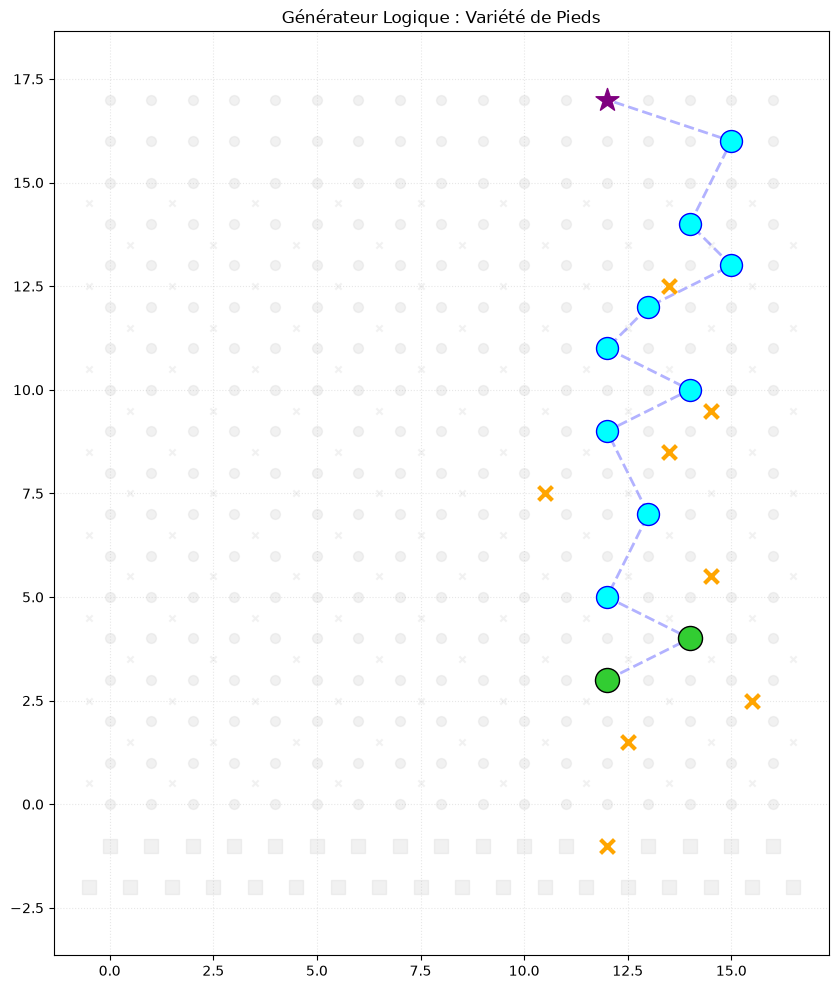

In [37]:
# --- 1. PRÉPARATION DES DONNÉES ---
if 'df' not in locals():
    df = pd.read_csv('dataset_kilter.csv')

if 'col' in df.columns: df = df.rename(columns={'col': 'x', 'row': 'y'})

if 'type' not in df.columns:
    def get_type(row):
        if row['y'] < 0: return 'kickboard'
        if row['role'] == 'foot': return 'foot_screw'
        return 'hand_bolt'
    df['type'] = df.apply(get_type, axis=1)

# --- 2. CALCUL DES ADJACENCES ---
print("Calcul des connexions...")
adjacencies = {}
MAX_DIST = 4.0 

hand_holds = df[df['type'] == 'hand_bolt']

for i in hand_holds.index:
    adjacencies[i] = {}
    x1, y1 = df.loc[i, 'x'], df.loc[i, 'y']
    for j in hand_holds.index:
        if i == j: continue
        x2, y2 = df.loc[j, 'x'], df.loc[j, 'y']
        if y2 < y1: continue
        
        dist = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        if dist <= MAX_DIST:
            adjacencies[i][j] = dist

# --- 3. FONCTIONS LOGIQUES (Avec variété de pieds) ---

def pick_start_holds():
    potential_starts = df[
        (df['type'] == 'hand_bolt') & (df['y'] >= 0) & (df['y'] <= 4)
    ].index.tolist()
    
    if not potential_starts: return []
    
    num_starts = random.choice([1, 2])
    if num_starts == 2:
        h1 = random.choice(potential_starts)
        neighbors = [h for h in potential_starts if abs(df.loc[h, 'x'] - df.loc[h1, 'x']) < 4 and h != h1]
        if neighbors:
            return [h1, random.choice(neighbors)]
        return [h1]
    else:
        return [random.choice(potential_starts)]

def get_supporting_feet(hand_hold_id, df):
    hand_y = df.loc[hand_hold_id]['y']
    hand_x = df.loc[hand_hold_id]['x']
    
    if hand_y > 14.5: return []

    feet_candidates = df[
        (df['y'] < hand_y - 0.5) & 
        (df['y'] > hand_y - 3.5) &
        (abs(df['x'] - hand_x) < 2.5)
    ].index.tolist()
    
    if not feet_candidates: return []

    screws = [f for f in feet_candidates if df.loc[f, 'type'] == 'foot_screw']
    bolts = [f for f in feet_candidates if df.loc[f, 'type'] == 'hand_bolt']
    
    # Variété : 50% Vis / 40% Bolt / 10% Rien
    if screws and random.random() < 0.5:
        return [random.choice(screws)]
    
    if bolts and random.random() < 0.4:
        return [random.choice(bolts)]
    
    if screws and random.random() < 0.5:
        return [random.choice(screws)]

    return []

def generate_realistic_route(start_holds_ids):
    route_hands = start_holds_ids[:]
    route_feet = []
    
    if not start_holds_ids: return [], []

    # Pieds de départ
    start_x_avg = np.mean([df.loc[h, 'x'] for h in start_holds_ids])
    kick_candidates = df[
        (df['type'] == 'kickboard') & 
        (abs(df['x'] - start_x_avg) < 3.5)
    ].index.tolist()
    
    if kick_candidates:
        nb_kicks = min(len(kick_candidates), random.choice([1, 2]))
        route_feet.extend(random.sample(kick_candidates, nb_kicks))
    else:
        fallback_kicks = df[(df['type'] == 'kickboard')].index.tolist()
        if fallback_kicks:
            closest_kick = min(fallback_kicks, key=lambda k: abs(df.loc[k, 'x'] - start_x_avg))
            route_feet.append(closest_kick)

    # Mains
    current_hold = sorted(start_holds_ids, key=lambda hid: df.loc[hid]['y'])[-1]
    while True:
        current_y = df.loc[current_hold]['y']
        if current_y >= 16.5: break
            
        possible_moves = []
        for neighbor, dist in adjacencies.get(current_hold, {}).items():
            neighbor_data = df.loc[neighbor]
            if neighbor_data['type'] != 'hand_bolt': continue
            if neighbor_data['y'] > current_y + 0.2:
                possible_moves.append(neighbor)
        
        if not possible_moves: break
        next_hand = random.choice(possible_moves)
        route_hands.append(next_hand)
        current_hold = next_hand

    # Pieds intermédiaires
    for hand in route_hands[:-1]:
        route_feet.extend(get_supporting_feet(hand, df))
        
    return route_hands, list(set(route_feet))

# --- 4. EXÉCUTION ---

starts = pick_start_holds()
hands_seq, feet_seq = generate_realistic_route(starts)
print(f"Voie générée : {len(hands_seq)} mains et {len(feet_seq)} pieds.")

# --- 5. VISUALISATION ---
plt.figure(figsize=(10, 12))

unused_mask = ~df.index.isin(hands_seq + feet_seq)
unused_bolts = df[unused_mask & (df['type'] == 'hand_bolt')]
unused_screws = df[unused_mask & (df['type'] == 'foot_screw')]
unused_kick = df[unused_mask & (df['y'] < 0)] 

# Fond
plt.scatter(unused_bolts['x'], unused_bolts['y'], c='lightgray', s=50, marker='o', alpha=0.3)
plt.scatter(unused_screws['x'], unused_screws['y'], c='lightgray', s=20, marker='x', alpha=0.3)
plt.scatter(unused_kick['x'], unused_kick['y'], c='lightgray', s=100, marker='s', alpha=0.3)

# Pieds
if feet_seq:
    feet_df = df.loc[feet_seq]
    kicks = feet_df[feet_df['y'] < 0]
    others = feet_df[feet_df['y'] >= 0]
    
    plt.scatter(others['x'], others['y'], c='orange', s=100, marker='x', linewidths=3, zorder=5)
    plt.scatter(kicks['x'], kicks['y'], c='orange', s=100, marker='x', linewidths=3, zorder=5)

# Mains
if hands_seq:
    plt.scatter(df.loc[starts, 'x'], df.loc[starts, 'y'], c='limegreen', s=300, edgecolors='black', zorder=10)
    
    top_id = hands_seq[-1]
    plt.scatter(df.loc[top_id, 'x'], df.loc[top_id, 'y'], c='purple', s=300, marker='*', zorder=10)
    
    inter = [h for h in hands_seq if h not in starts and h != top_id]
    if inter:
        plt.scatter(df.loc[inter, 'x'], df.loc[inter, 'y'], c='cyan', s=250, edgecolors='blue', marker='o', zorder=8)
    
    plt.plot(df.loc[hands_seq, 'x'], df.loc[hands_seq, 'y'], c='blue', alpha=0.3, linewidth=2, linestyle='--')

plt.title("Générateur Logique : Variété de Pieds")
plt.axis('equal')
plt.grid(True, linestyle=':', alpha=0.3) # Je remets la grille discrète
# plt.legend()  <--- J'ai supprimé cette ligne !
plt.show()

In [38]:
# --- CONFIGURATION ---
INPUT_FILE = 'dataset_kilter.csv'
OUTPUT_X = 'X_kilter_tensor.npy'
OUTPUT_Y = 'y_kilter_labels.npy'
OUTPUT_MAPPING = 'grade_mapping.csv'

# Dimensions de la Kilter Board (selon tes données)
# Lignes : de -2 à 17 -> Total 20 lignes
GRID_H = 20 
GRID_W = 17 
CHANNELS = 4  # Start, Middle, Foot, Top

ROLE_MAP = {'start': 0, 'middle': 1, 'foot': 2, 'top': 3}

def create_tensors():
    print("Chargement du dataset...")
    df = pd.read_csv(INPUT_FILE)
    
    # 1. Encodage des Grades (V1 -> 0, V2 -> 1...)
    # On trie pour que V0 < V1 < V10 soit respecté (attention au tri alpha "V10" < "V2")
    # Astuce : on extrait le chiffre pour trier correctement
    unique_grades = sorted(df['grade'].unique(), key=lambda x: int(x[1:]) if x[1:].isdigit() else 99)
    grade_to_id = {g: i for i, g in enumerate(unique_grades)}
    
    # Sauvegarder le mapping pour plus tard
    pd.DataFrame(list(grade_to_id.items()), columns=['grade', 'id']).to_csv(OUTPUT_MAPPING, index=False)
    print(f"Grades détectés : {unique_grades}")

    # 2. Création des matrices vides
    # On groupe par image_id pour traiter bloc par bloc
    grouped = df.groupby('image_id')
    n_samples = len(grouped)
    
    # Tensor X : (Nombre_Blocs, Hauteur, Largeur, Canaux)
    X = np.zeros((n_samples, GRID_H, GRID_W, CHANNELS), dtype=np.uint8)
    y = np.zeros(n_samples, dtype=np.int32)
    
    print(f"Création du Tensor de taille : {X.shape}...")
    
    for idx, (img_id, group) in enumerate(grouped):
        # Récupération du grade (le premier de la liste, ils sont identiques pour une image)
        g_str = group['grade'].iloc[0]
        y[idx] = grade_to_id.get(g_str, -1)
        
        for _, row in group.iterrows():
            # Conversion Grille -> Indice Matrice
            
            # AXE X (Colonnes) : 0 à 16
            # Attention : Tes pieds de kickboard sont en .5 (ex: 3.5).
            # Pour la matrice, on doit choisir une case. On arrondit à l'inférieur (int).
            # 3.5 deviendra l'index 3. C'est une approximation nécessaire pour une grille simple.
            c_idx = int(row['col'])
            
            # AXE Y (Lignes) : -2 à 17
            # On décale de +2 pour avoir des indices positifs (0 à 19)
            # -2 (Kickboard) -> Index 0
            r_idx = int(row['row']) + 2
            
            role_idx = ROLE_MAP.get(row['role'], 1) # Middle par défaut
            
            # Sécurité bornes (au cas où)
            if 0 <= r_idx < GRID_H and 0 <= c_idx < GRID_W:
                X[idx, r_idx, c_idx, role_idx] = 1
                
    # 3. Sauvegarde
    np.save(OUTPUT_X, X)
    np.save(OUTPUT_Y, y)
    print(f"✅ Terminé ! Tensors sauvegardés.")
    print(f"X (Données) : {OUTPUT_X}")
    print(f"y (Labels)  : {OUTPUT_Y}")

create_tensors()

Chargement du dataset...
Grades détectés : ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10']
Création du Tensor de taille : (13431, 20, 17, 4)...
✅ Terminé ! Tensors sauvegardés.
X (Données) : X_kilter_tensor.npy
y (Labels)  : y_kilter_labels.npy


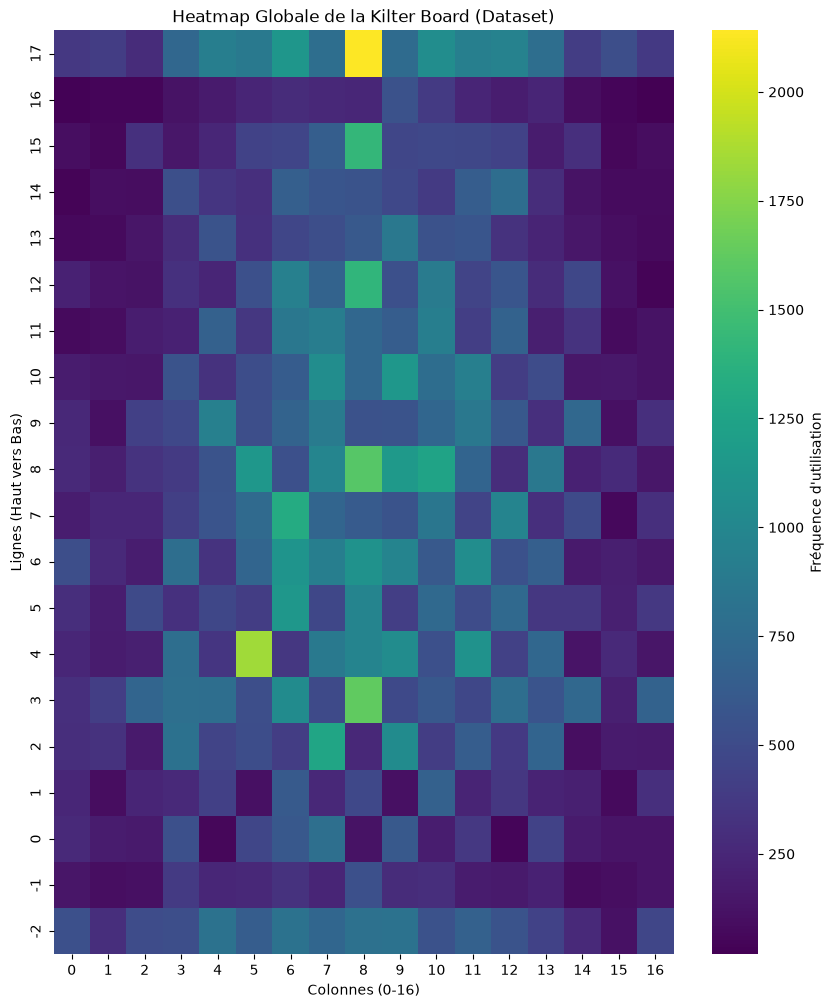

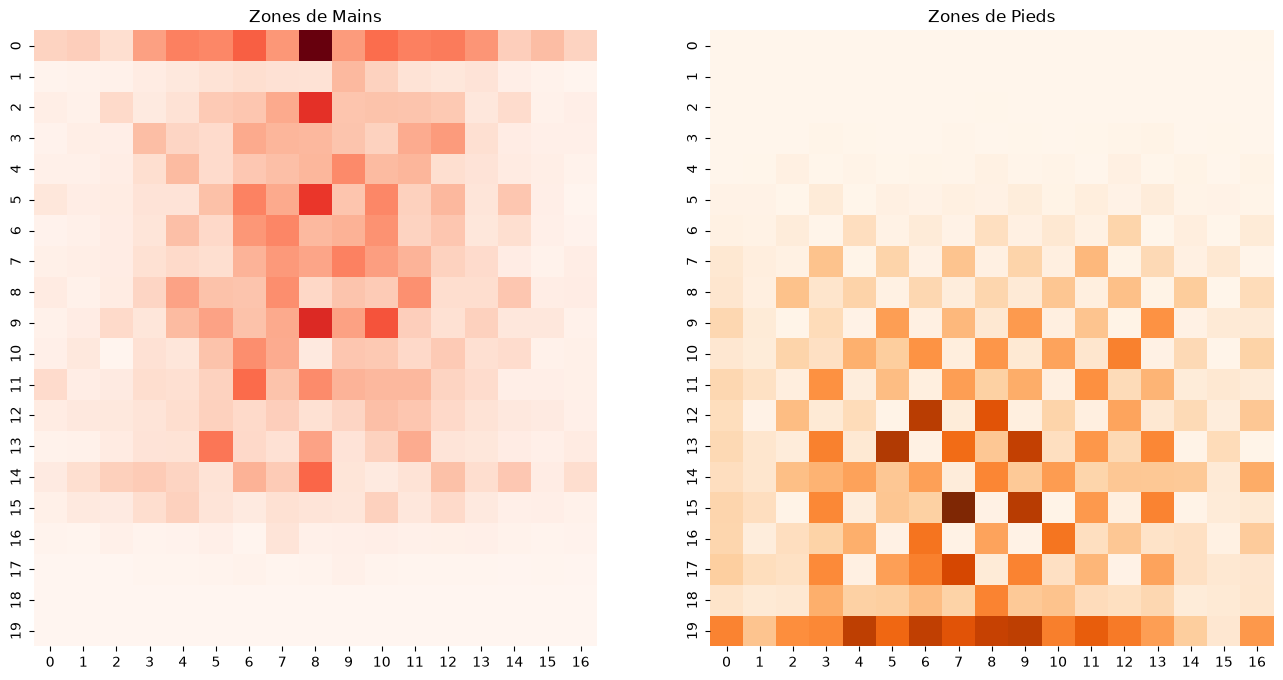

In [39]:
INPUT_FILE = 'dataset_kilter.csv'

def plot_heatmaps():
    df = pd.read_csv(INPUT_FILE)
    
    # On prépare la grille pour la Heatmap
    # On va faire une matrice 2D simple qui compte juste le nombre de fois qu'une prise est utilisée
    heatmap_data = np.zeros((20, 17)) # 20 Lignes (de -2 à 17), 17 Colonnes
    
    # Remplissage
    for _, row in df.iterrows():
        r_idx = int(row['row']) + 2 # Décalage comme tout à l'heure
        c_idx = int(row['col'])
        
        if 0 <= r_idx < 20 and 0 <= c_idx < 17:
            heatmap_data[r_idx, c_idx] += 1

    # Visualisation
    plt.figure(figsize=(10, 12))
    
    # On utilise Seaborn pour une belle heatmap
    # On inverse l'axe Y pour avoir le haut du mur en haut du graphe
    ax = sns.heatmap(np.flipud(heatmap_data), cmap="viridis", annot=False, cbar_kws={'label': 'Fréquence d\'utilisation'})
    
    plt.title("Heatmap Globale de la Kilter Board (Dataset)")
    plt.xlabel("Colonnes (0-16)")
    plt.ylabel("Lignes (Haut vers Bas)")
    
    # Ajustement des étiquettes Y pour qu'elles correspondent aux vraies lignes
    # L'index 0 du graphe (haut) correspond à la ligne 17
    # L'index 19 du graphe (bas) correspond à la ligne -2
    yticks = np.arange(0.5, 20.5, 1)
    ylabels = [str(17 - i) for i in range(20)]
    plt.yticks(yticks, ylabels)
    
    plt.show()

    # --- HEATMAP PAR ROLE (Optionnel) ---
    # Séparer Mains et Pieds
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    
    # Filtrer Mains
    hands = df[df['role'].isin(['start', 'middle', 'top'])]
    h_map = np.zeros((20, 17))
    for _, row in hands.iterrows():
        h_map[int(row['row'])+2, int(row['col'])] += 1
        
    sns.heatmap(np.flipud(h_map), ax=ax1, cmap="Reds", cbar=False)
    ax1.set_title("Zones de Mains")
    
    # Filtrer Pieds
    feet = df[df['role'] == 'foot']
    f_map = np.zeros((20, 17))
    for _, row in feet.iterrows():
        f_map[int(row['row'])+2, int(row['col'])] += 1
        
    sns.heatmap(np.flipud(f_map), ax=ax2, cmap="Oranges", cbar=False)
    ax2.set_title("Zones de Pieds")
    
    plt.show()

plot_heatmaps()

Chargement des Tensors...
Dataset original : 13431 blocs
Dataset augmenté (x2) : 26862 blocs

🚀 Démarrage de l'entraînement optimisé...
Epoch 1/50
672/672 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.1955 - loss: 2.5613 - val_accuracy: 0.2526 - val_loss: 2.1478 - learning_rate: 5.0000e-04
Epoch 2/50
672/672 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.2450 - loss: 2.2102 - val_accuracy: 0.2808 - val_loss: 2.0231 - learning_rate: 5.0000e-04
Epoch 3/50
672/672 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.2750 - loss: 2.0439 - val_accuracy: 0.3021 - val_loss: 1.8932 - learning_rate: 5.0000e-04
Epoch 4/50
672/672 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.2875 - loss: 1.9382 - val_accuracy: 0.3069 - val_loss: 1.8363 - learning_rate: 5.0000e-04
Epoch 5/50
672/672 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3063 - loss: 1.8468 - val_accuracy: 0.3246 - val_loss: 1.7516 - learning_rate: 5.0000e-04
Epoch 6/50
672/672 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3164 - loss: 1.788

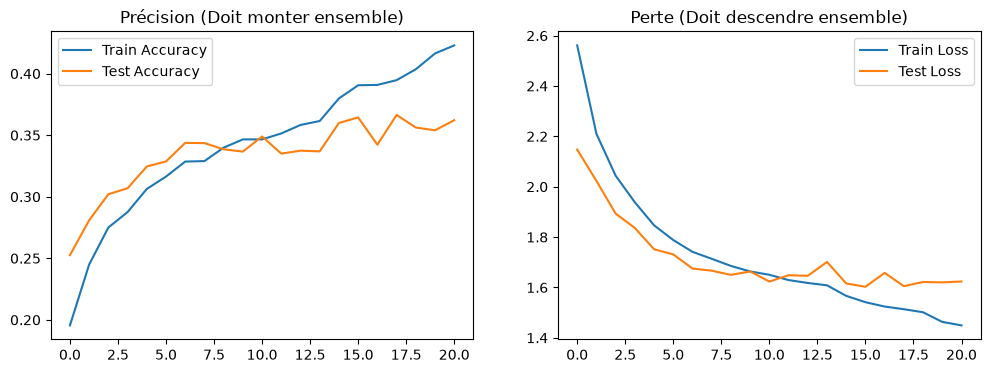

Génération des prédictions...
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


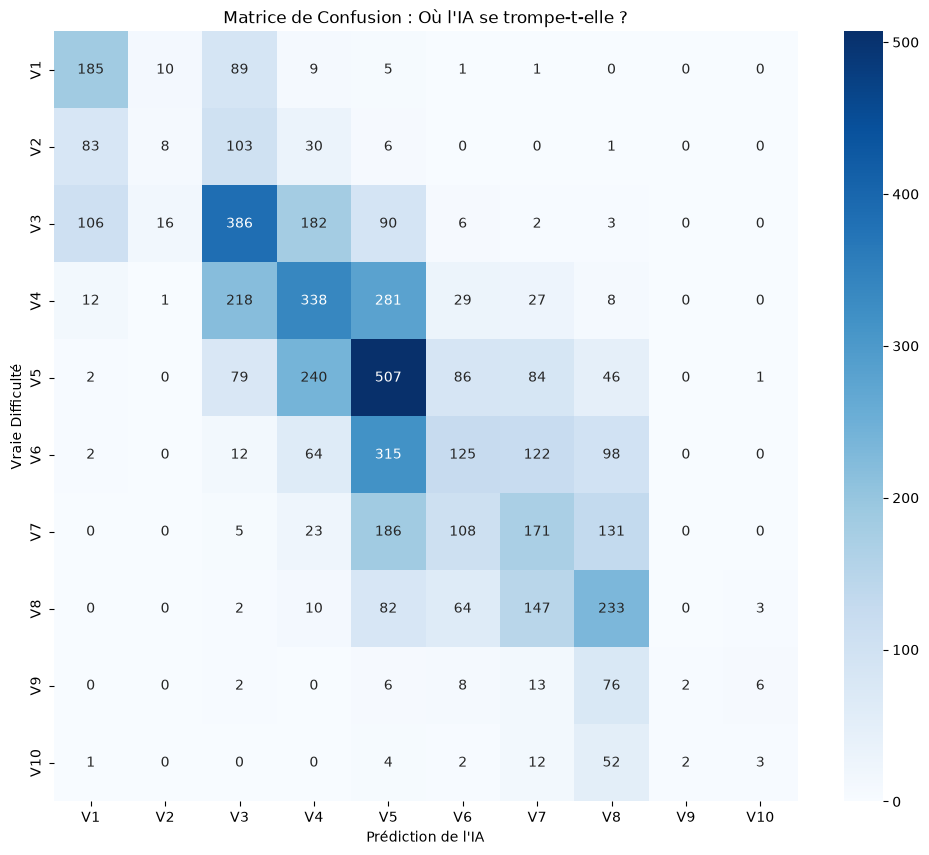


✅ Précision stricte (Exacte) : 36.22%
✅ Précision réelle (À +/- 1 grade) : 76.01%


In [ ]:
# --- 1. CHARGEMENT ---
print("Chargement des Tensors...")
if not os.path.exists('X_kilter_tensor.npy'):
    print("ERREUR : Fichiers manquants.")
else:
    X = np.load('X_kilter_tensor.npy')
    y = np.load('y_kilter_labels.npy')
    mapping_df = pd.read_csv('grade_mapping.csv')
    num_classes = len(mapping_df)

    # --- ASTUCE PRO : DATA AUGMENTATION (MIROIR) ---
    # La Kilter Board est symétrique. On peut doubler le dataset en inversant l'axe X (largeur).
    print(f"Dataset original : {X.shape[0]} blocs")
    
    # On crée les versions miroirs
    X_flipped = np.flip(X, axis=2) # Axis 2 = Largeur (17 colonnes)
    
    # On fusionne tout (Original + Miroir)
    X_full = np.concatenate((X, X_flipped), axis=0)
    y_full = np.concatenate((y, y), axis=0)
    
    print(f"Dataset augmenté (x2) : {X_full.shape[0]} blocs")

    # --- 2. SÉPARATION ---
    X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=42)

    # --- 3. MODÈLE RENFORCÉ (Anti-Overfitting) ---
    model = models.Sequential([
        layers.Input(shape=(20, 17, 4)),
        
        # Bloc Convolutif 1 + BatchNormalization
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),       # Stabilise l'apprentissage
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),               # Petit oubli volontaire ici
        
        # Bloc Convolutif 2
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),

        # Bloc Convolutif 3 (Optionnel, pour capter plus de complexité)
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        
        # Classification
        layers.Flatten(),
        
        # Régularisation L2 (Pénalité mathématique pour éviter les valeurs extrêmes)
        layers.Dense(256, kernel_regularizer=regularizers.l2(0.001)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        
        # Gros Dropout avant la décision finale
        layers.Dropout(0.5), 
        
        layers.Dense(num_classes, activation='softmax')
    ])

    # Utilisation d'un Learning Rate un peu plus lent pour être précis
    optimizer = tensorflow.keras.optimizers.Adam(learning_rate=0.0005)

    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    # --- 4. CALLBACKS (Le Pilote Automatique) ---
    my_callbacks = [
        # Arrête si la validation ne s'améliore plus depuis 5 tours
        callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        
        # Réduit la vitesse d'apprentissage si on bloque
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
    ]

    print("\n🚀 Démarrage de l'entraînement optimisé...")
    # On met plus d'epochs (50) car l'EarlyStopping arrêtera tout seul quand ce sera prêt
    history = model.fit(X_train, y_train, epochs=50, 
                        validation_data=(X_test, y_test),
                        batch_size=32,
                        callbacks=my_callbacks) # On ajoute les callbacks ici

    # --- 5. VISUALISATION ---
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Test Accuracy')
    plt.title('Précision (Doit monter ensemble)')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Test Loss')
    plt.title("Perte (Doit descendre ensemble)")
    plt.legend()
    plt.show()

    # 1. L'IA fait ses prédictions sur l'examen (Test)
print("Génération des prédictions...")
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. On récupère les noms des grades
grade_labels = [mapping_df[mapping_df['id'] == i]['grade'].values[0] for i in range(len(mapping_df))]

# 3. Création de la Matrice
cm = confusion_matrix(y_test, y_pred)

# 4. Affichage
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=grade_labels, 
            yticklabels=grade_labels)
plt.xlabel('Prédiction de l\'IA')
plt.ylabel('Vraie Difficulté')
plt.title('Matrice de Confusion : Où l\'IA se trompe-t-elle ?')
plt.show()

# 5. Calcul de la "Précision à +/- 1 grade"
# On considère que l'IA a bon si elle tombe juste OU à 1 niveau d'écart
diff = np.abs(y_test - y_pred)
accuracy_relaxed = np.mean(diff <= 1)
print(f"\nPrécision Exacte : {history.history['val_accuracy'][-1]:.2%}")
print(f"Précision à +/- 1 grade : {accuracy_relaxed:.2%}")

Démarrage du moteur de recherche...
🎯 Recherche d'un bloc de difficulté : V8
⏳ Essai 50/200 -> IA a vu : V8 (Cible: V8)

✅ TROUVÉ à l'essai #51 !
⏱️ Temps de recherche : 2.67 secondes


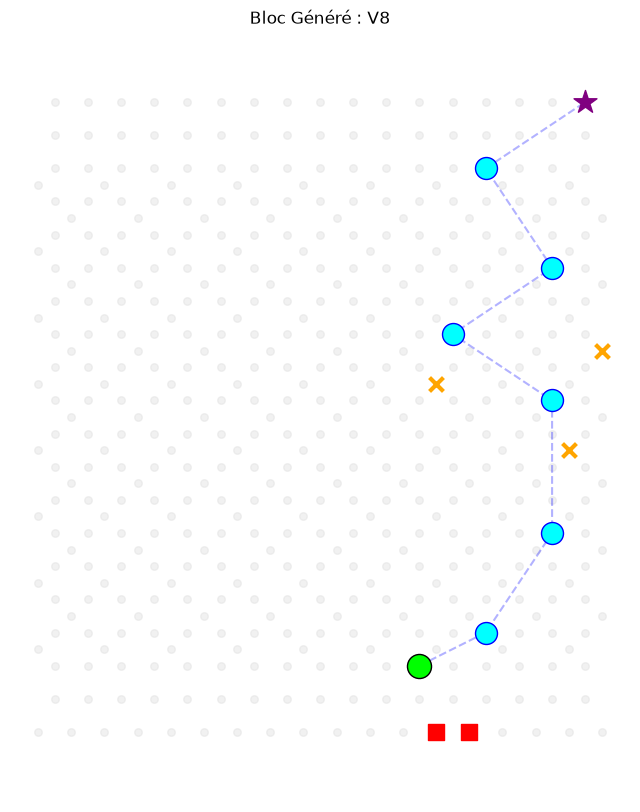

In [41]:
# --- 1. PRÉPARATION DU TENSOR (Pour l'IA) ---
def prepare_tensor_for_ai(hands, feet, df):
    # Création d'une image vide (1 bloc, 20 lignes, 17 colonnes, 4 canaux)
    X_input = np.zeros((1, 20, 17, 4), dtype=np.uint8)
    
    # Canal 0 : Start (Vert)
    for h in hands[:2]: 
        r, c = int(df.loc[h, 'y']) + 2, int(df.loc[h, 'x'])
        if 0 <= r < 20 and 0 <= c < 17: X_input[0, r, c, 0] = 1
            
    # Canal 1 : Middle (Cyan)
    for h in hands[2:-1]:
        r, c = int(df.loc[h, 'y']) + 2, int(df.loc[h, 'x'])
        if 0 <= r < 20 and 0 <= c < 17: X_input[0, r, c, 1] = 1
            
    # Canal 2 : Feet (Orange)
    for f in feet:
        r, c = int(math.floor(df.loc[f, 'y'])) + 2, int(math.floor(df.loc[f, 'x']))
        if 0 <= r < 20 and 0 <= c < 17: X_input[0, r, c, 2] = 1
            
    # Canal 3 : Top (Rose)
    if hands:
        top = hands[-1]
        r, c = int(df.loc[top, 'y']) + 2, int(df.loc[top, 'x'])
        if 0 <= r < 20 and 0 <= c < 17: X_input[0, r, c, 3] = 1
        
    return X_input

# --- 2. FONCTION DE GÉNÉRATION CIBLÉE (CORRIGÉE) ---
def generate_block_by_grade(target_grade, max_attempts=500):
    print(f"🎯 Recherche d'un bloc de difficulté : {target_grade}")
    
    # --- CORRECTION DE L'ERREUR 'UnboundLocalError' ---
    # On récupère le mapping de manière sûre
    if 'mapping_df' in globals():
        grade_map = globals()['mapping_df']
    else:
        try:
            grade_map = pd.read_csv('grade_mapping.csv')
        except:
            print("❌ Erreur : 'grade_mapping.csv' introuvable.")
            return None, None
            
    start_time = time.time()
    
    for i in range(max_attempts):
        # 1. Générer un bloc au hasard
        starts = pick_start_holds()
        hands, feet = generate_realistic_route(starts)
        
        # Si génération ratée (trop court), on passe
        if len(hands) < 4: continue 
        
        # 2. Convertir en image pour l'IA
        tensor = prepare_tensor_for_ai(hands, feet, df)
        
        # 3. L'IA juge le bloc
        pred_probs = model.predict(tensor, verbose=0)
        pred_id = np.argmax(pred_probs)
        
        # On récupère le grade prédit
        pred_grade = grade_map.loc[grade_map['id'] == pred_id, 'grade'].values[0]
        
        # Petit affichage pour patienter (tous les 10 essais)
        if i % 10 == 0:
            sys.stdout.write(f"\r⏳ Essai {i}/{max_attempts} -> IA a vu : {pred_grade} (Cible: {target_grade})")
            sys.stdout.flush()
        
        # 4. BINGO ?
        # On compare en string pour éviter les erreurs de type (12 vs "12")
        if str(pred_grade) == str(target_grade):
            print(f"\n\n✅ TROUVÉ à l'essai #{i+1} !")
            print(f"⏱️ Temps de recherche : {time.time() - start_time:.2f} secondes")
            return hands, feet
            
    print(f"\n\n❌ Échec. Après {max_attempts} essais, l'IA n'a généré que des blocs d'autres niveaux.")
    return None, None

# --- 3. LANCEMENT ---
import time

# CHOISIS TON GRADE ICI (Vérifie bien ton fichier mapping pour savoir si c'est "12" ou "V5")
TARGET = "V8" 

print("Démarrage du moteur de recherche...")
hands_res, feet_res = generate_block_by_grade(TARGET, max_attempts=200)

# --- 4. VISUALISATION ---
if hands_res:
    plt.figure(figsize=(8, 10))
    
    # Fond
    unused_mask = ~df.index.isin(hands_res + feet_res)
    unused = df[unused_mask]
    plt.scatter(unused['x'], unused['y'], c='lightgray', s=30, alpha=0.3)
    
    # Pieds
    if feet_res:
        f_df = df.loc[feet_res]
        kicks = f_df[f_df['y'] < 0]
        others = f_df[f_df['y'] >= 0]
        plt.scatter(others['x'], others['y'], c='orange', s=100, marker='x', linewidths=3, zorder=5)
        plt.scatter(kicks['x'], kicks['y'], c='red', s=120, marker='s', zorder=5)
    
    # Mains
    plt.plot(df.loc[hands_res, 'x'], df.loc[hands_res, 'y'], c='blue', alpha=0.3, linestyle='--')
    plt.scatter(df.loc[hands_res[0], 'x'], df.loc[hands_res[0], 'y'], c='lime', s=300, edgecolors='black', zorder=10)
    plt.scatter(df.loc[hands_res[-1], 'x'], df.loc[hands_res[-1], 'y'], c='purple', s=300, marker='*', zorder=10)
    
    inter = hands_res[1:-1]
    if inter:
        plt.scatter(df.loc[inter, 'x'], df.loc[inter, 'y'], c='cyan', s=250, edgecolors='blue', zorder=8)

    plt.title(f"Bloc Généré : {TARGET}")
    plt.axis('equal')
    plt.axis('off')
    plt.show()